In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

print("Bibliotecas importadas com sucesso!")

Matplotlib is building the font cache; this may take a moment.


Bibliotecas importadas com sucesso!


In [2]:
# Carregar o dataset
df = pd.read_csv("creditcard.csv")

# Visualizar as primeiras cinco transações
df.head()

FileNotFoundError: [Errno 2] No such file or directory: 'creditcard.csv'

In [3]:
# Carregar o dataset
df = pd.read_csv("creditcard.csv")

# Visualizar as primeiras cinco transações
df.head()

FileNotFoundError: [Errno 2] No such file or directory: 'creditcard.csv'

In [6]:
df = pd.read_csv("creditcard.csv")
df.head()


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [7]:
# Quantidade total de transações
print("Total de transações:", len(df))

# Quantidade de transações por classe
print("\nDistribuição das classes:")
print(df["Class"].value_counts())

# Porcentagem de cada classe
print("\nPorcentagem:")
print(df["Class"].value_counts(normalize=True) * 100)

Total de transações: 284807

Distribuição das classes:
Class
0    284315
1       492
Name: count, dtype: int64

Porcentagem:
Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64


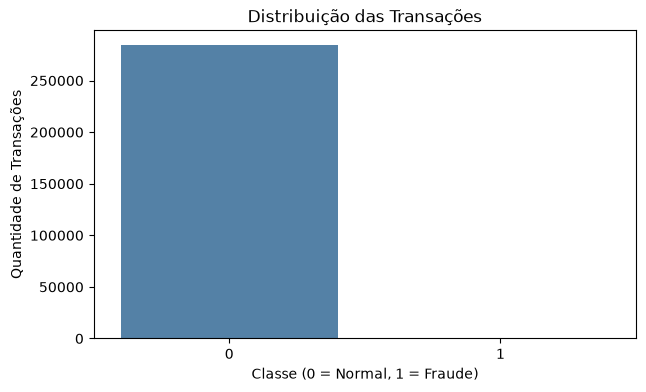

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 4))

sns.countplot(
    data=df,
    x="Class",
    hue="Class",
    palette=["steelblue", "tomato"],
    legend=False
)

plt.title("Distribuição das Transações")
plt.xlabel("Classe (0 = Normal, 1 = Fraude)")
plt.ylabel("Quantidade de Transações")

plt.show()

In [9]:
# Criar uma cópia dos dados
df_modelo = df.copy()

# Criar variável com logaritmo do valor da transação
df_modelo["Log_Amount"] = np.log1p(df_modelo["Amount"])

# Visualizar as novas colunas
df_modelo[["Amount", "Log_Amount", "Class"]].head()


,Amount,Log_Amount,Class
0,149.62,5.014760,0
1,2.69,1.305626,0
2,378.66,5.939276,0
3,123.50,4.824306,0
4,69.99,4.262539,0


In [10]:
from sklearn.model_selection import train_test_split

# Separar variáveis explicativas e variável alvo
X = df_modelo.drop(columns=["Class"])
y = df_modelo["Class"]

# Dividir em treino (80%) e teste (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Conferir os resultados
print("Transações de treino:", len(X_train))
print("Transações de teste:", len(X_test))

print("\nFraudes no treino:", y_train.sum())
print("Fraudes no teste:", y_test.sum())

Transações de treino: 227845
Transações de teste: 56962

Fraudes no treino: 394
Fraudes no teste: 98


In [11]:
from sklearn.preprocessing import StandardScaler

# Criar o padronizador
scaler = StandardScaler()

# Ajustar somente nos dados de treino
X_train_scaled = scaler.fit_transform(X_train)

# Aplicar a mesma transformação aos dados de teste
X_test_scaled = scaler.transform(X_test)

# Conferir os resultados
print("Formato do treino:", X_train_scaled.shape)
print("Formato do teste:", X_test_scaled.shape)

Formato do treino: (227845, 31)
Formato do teste: (56962, 31)


In [14]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix

# Criar o modelo
modelo_lr = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

# Treinar com os dados de treino
modelo_lr.fit(X_train_scaled, y_train)

# Fazer previsões no conjunto de teste
y_pred_lr = modelo_lr.predict(X_test_scaled)

# Avaliar o modelo
print("REGRESSÃO LOGÍSTICA")
print("\nRelatório de classificação:")
print(classification_report(y_test, y_pred_lr, digits=4))

print("\nMatriz de confusão:")
print(confusion_matrix(y_test, y_pred_lr))

REGRESSÃO LOGÍSTICA

Relatório de classificação:
              precision    recall  f1-score   support

           0     0.9999    0.9757    0.9876     56864
           1     0.0612    0.9184    0.1147        98

    accuracy                         0.9756     56962
   macro avg     0.5305    0.9470    0.5512     56962
weighted avg     0.9982    0.9756    0.9861     56962


Matriz de confusão:
[[55483  1381]
 [    8    90]]


In [15]:
from sklearn.ensemble import RandomForestClassifier

# Criar o modelo Random Forest
modelo_rf = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Treinar o modelo
modelo_rf.fit(X_train, y_train)

# Fazer previsões
y_pred_rf = modelo_rf.predict(X_test)

# Avaliar os resultados
print("RANDOM FOREST")
print("\nRelatório de classificação:")
print(classification_report(y_test, y_pred_rf, digits=4))

print("\nMatriz de confusão:")
print(confusion_matrix(y_test, y_pred_rf))

RANDOM FOREST

Relatório de classificação:
              precision    recall  f1-score   support

           0     0.9997    0.9999    0.9998     56864
           1     0.9186    0.8061    0.8587        98

    accuracy                         0.9995     56962
   macro avg     0.9591    0.9030    0.9292     56962
weighted avg     0.9995    0.9995    0.9995     56962


Matriz de confusão:
[[56857     7]
 [   19    79]]


In [16]:
from xgboost import XGBClassifier

# Calcular o peso da classe minoritária
peso_fraude = (y_train == 0).sum() / (y_train == 1).sum()

# Criar o modelo XGBoost
modelo_xgb = XGBClassifier(
    n_estimators=100,
    max_depth=4,
    learning_rate=0.1,
    scale_pos_weight=peso_fraude,
    random_state=42,
    n_jobs=-1,
    eval_metric="logloss"
)

# Treinar o modelo
modelo_xgb.fit(X_train, y_train)

# Fazer previsões
y_pred_xgb = modelo_xgb.predict(X_test)

# Avaliar os resultados
print("XGBOOST")
print("\nRelatório de classificação:")
print(classification_report(y_test, y_pred_xgb, digits=4))

print("\nMatriz de confusão:")
print(confusion_matrix(y_test, y_pred_xgb))

XGBOOST

Relatório de classificação:
              precision    recall  f1-score   support

           0     0.9998    0.9970    0.9984     56864
           1     0.3346    0.8673    0.4830        98

    accuracy                         0.9968     56962
   macro avg     0.6672    0.9322    0.7407     56962
weighted avg     0.9986    0.9968    0.9975     56962


Matriz de confusão:
[[56695   169]
 [   13    85]]


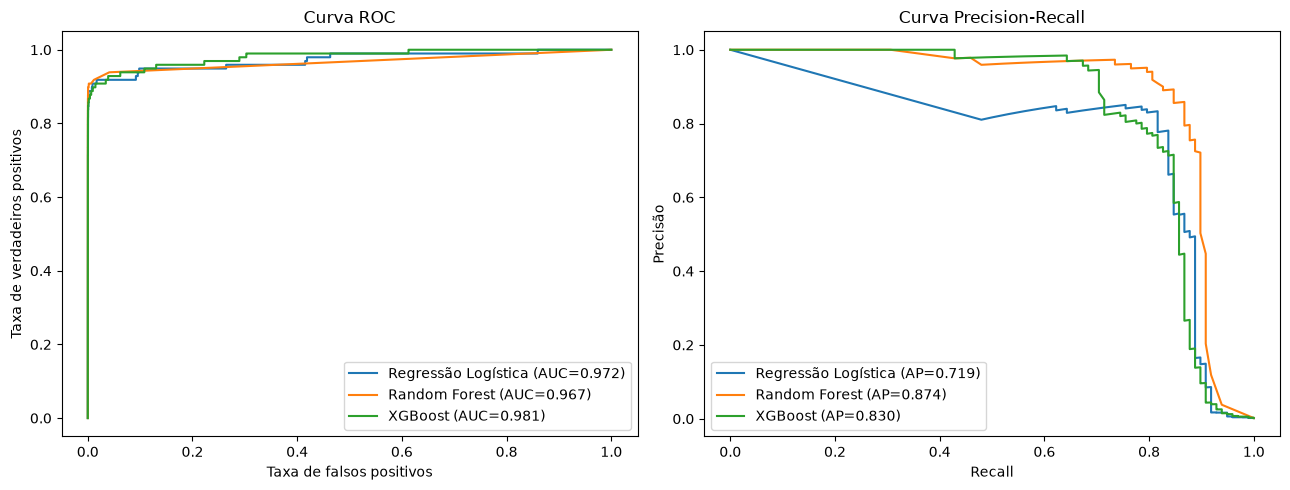

In [17]:
from sklearn.metrics import (
    roc_curve, precision_recall_curve,
    roc_auc_score, average_precision_score
)

modelos = {
    "Regressão Logística": (modelo_lr, X_test_scaled),
    "Random Forest": (modelo_rf, X_test),
    "XGBoost": (modelo_xgb, X_test)
}

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for nome, (modelo, dados) in modelos.items():
    probabilidades = modelo.predict_proba(dados)[:, 1]

    # Curva ROC
    fpr, tpr, _ = roc_curve(y_test, probabilidades)
    auc = roc_auc_score(y_test, probabilidades)

    axes[0].plot(fpr, tpr, label=f"{nome} (AUC={auc:.3f})")

    # Curva Precision-Recall
    precision, recall, _ = precision_recall_curve(
        y_test, probabilidades
    )
    ap = average_precision_score(y_test, probabilidades)

    axes[1].plot(recall, precision, label=f"{nome} (AP={ap:.3f})")

axes[0].set_title("Curva ROC")
axes[0].set_xlabel("Taxa de falsos positivos")
axes[0].set_ylabel("Taxa de verdadeiros positivos")
axes[0].legend()

axes[1].set_title("Curva Precision-Recall")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precisão")
axes[1].legend()

plt.tight_layout()
plt.show()

In [18]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Probabilidades previstas pelo Random Forest
prob_rf = modelo_rf.predict_proba(X_test)[:, 1]

# Comparar diferentes thresholds
for threshold in [0.3, 0.5, 0.7]:
    y_pred = (prob_rf >= threshold).astype(int)

    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)

    print(f"Threshold: {threshold}")
    print(f"Precisão: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1-score: {f1:.4f}")
    print("-" * 30)

Threshold: 0.3
Precisão: 0.8095
Recall: 0.8673
F1-score: 0.8374
------------------------------
Threshold: 0.5
Precisão: 0.9091
Recall: 0.8163
F1-score: 0.8602
------------------------------
Threshold: 0.7
Precisão: 0.9605
Recall: 0.7449
F1-score: 0.8391
------------------------------


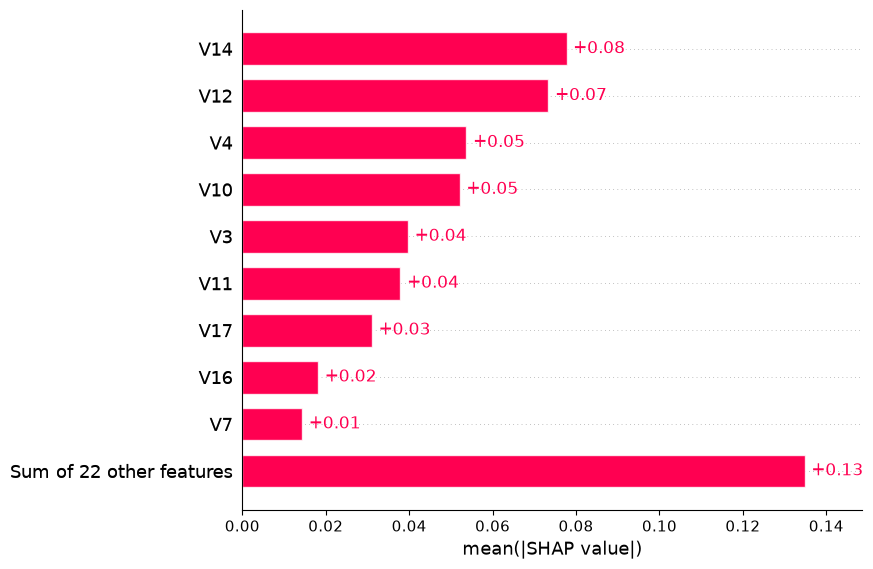

In [19]:
import shap

# Selecionar uma pequena amostra
X_amostra = X_test.sample(n=20, random_state=42)

# Criar o explicador SHAP
explainer = shap.TreeExplainer(modelo_rf)

# Calcular os valores SHAP
shap_values = explainer(X_amostra)

# Mostrar a importância das variáveis para a classe fraude
shap.plots.bar(shap_values[:, :, 1], max_display=10)